# Quantum Lock: a small quantum enigma machine

Phase-modulation quantum data locking (Lupo, Wilde & Lloyd, *PRA* **90**, 022326, 2014), second protocol of their Sec. II.A ("QDL from random unitaries").

- **Alice** encodes message $m$ with key $k$ as $|\psi_{m,k}\rangle = D_k F |m\rangle$ ($F$ = QFT, $D_k$ = random diagonal phase mask)
- **Bob** decodes with $F^\dagger D_k^\dagger$ and measures in the computational basis
- Read-outs compared: **correct key**, **wrong key**, **no key** ($F^\dagger$ only), **direct measurement**

Running all cells (*Runtime → Run all*, a few minutes) writes every file used by the report:
`results.tex` (numbers), `table_n.tex`, `table_K.tex`, `fig_circuit.pdf`, `fig_distributions.pdf`, plus `report_files.zip` containing all of them.

In [1]:
%pip install -q "qiskit>=1.2" matplotlib pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.3 MB/s eta 0:00:00


In [2]:
import time
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Gate
from qiskit.circuit.library import QFTGate, DiagonalGate
from qiskit.quantum_info import Statevector, Operator

SEED = 2026                    # fixed seed -> the same phase codebook every run
N_QUBITS = 6                   # message qubits n, d = 2**n = 64 messages
N_KEYS = 4                     # K = 4 keys (2-bit classical key)
M_EX, K_EX, KP_EX = 37, 0, 2   # example: message, true key, wrong key
M_EX2 = 12                     # second message shown in Fig. 2
N_SEEDS = 10                   # further codebooks for the variation study
SEEDS = [SEED + 100 + i for i in range(N_SEEDS)]   # 2126 ... 2135

## 1. Phase codebook

For each key $k$: $d$ angles $\theta_{k,x}$, uniform in $[0, 2\pi)$.
Variants: binary $\theta \in \{0, \pi\}$, and linear $\theta_x = 2\pi s_k x / d$ (a classical shift cipher, used only for comparison).

In [3]:
def make_codebook(n, K, seed=SEED, binary=False, linear=False):
    """Phase angles theta[k, x] for K keys and d = 2**n basis states.
    binary=True : phases in {0, pi} (random signs)
    linear=True : theta_x = 2 pi s_k x / d, which only shifts the message (classical shift cipher)"""
    rng = np.random.default_rng(seed)
    d = 2**n
    if linear:
        shifts = rng.choice(d, size=K, replace=False)
        return 2 * np.pi * np.outer(shifts, np.arange(d)) / d
    if binary:
        return np.pi * rng.integers(0, 2, size=(K, d))
    return rng.uniform(0, 2 * np.pi, size=(K, d))

theta = make_codebook(N_QUBITS, N_KEYS)
print("codebook shape (K, d):", theta.shape)
print("first phases of key 0:", np.round(theta[0, :5], 3))

codebook shape (K, d): (4, 64)
first phases of key 0: [1.124 4.021 2.936 2.328 2.23 ]


## 2. Circuits (report Sec. IV-A)

Only the message register is quantum; the key is a classical index choosing the phase circuit.

In [4]:
def prepare_message(n, m):
    """Basis state |m> (Qiskit convention: qubit q holds bit q of m)."""
    qc = QuantumCircuit(n)
    for q in range(n):
        if (m >> q) & 1:
            qc.x(q)
    return qc

def lock_circuit(n, theta_k):
    """Alice: |m> -> D_k F |m>."""
    qc = QuantumCircuit(n)
    qc.append(QFTGate(n), range(n))
    qc.append(DiagonalGate(list(np.exp(1j * theta_k))), range(n))
    return qc

def unlock_circuit(n, theta_k=None):
    """Bob: D_k^dagger then F^dagger.  theta_k=None -> no phase correction (F^dagger only)."""
    qc = QuantumCircuit(n)
    if theta_k is not None:
        qc.append(DiagonalGate(list(np.exp(-1j * theta_k))), range(n))
    qc.append(QFTGate(n).inverse(), range(n))
    return qc

def probs(sv):
    """Outcome distribution as an array indexed by the integer outcome j."""
    p = np.zeros(2**sv.num_qubits)
    for bits, val in sv.probabilities_dict().items():
        p[int(bits, 2)] = val
    return p

In [5]:
# Quick sanity check on one message
sv = Statevector.from_instruction(prepare_message(N_QUBITS, M_EX).compose(lock_circuit(N_QUBITS, theta[K_EX])))
print("|amplitudes| of locked state:", np.unique(np.round(np.abs(sv.data), 8)))   # all 1/sqrt(64) = 0.125
print("P(m) with correct key:", round(probs(sv.evolve(unlock_circuit(N_QUBITS, theta[K_EX])))[M_EX], 6))
print("P(m) with wrong key  :", round(probs(sv.evolve(unlock_circuit(N_QUBITS, theta[KP_EX])))[M_EX], 6))

|amplitudes| of locked state: [0.125]
P(m) with correct key: 1.0
P(m) with wrong key  : 0.002837


## 3. One-qubit worked example (report Sec. III)

For $d = 2$ the QFT is a Hadamard. A wrong key leaves a residual phase $\Delta = \varphi_k - \varphi_{k'}$ and $P(\text{right bit}) = \cos^2(\Delta/2)$.

In [6]:
theta1 = make_codebook(1, N_KEYS)                    # K x 2 phases for n = 1
phi = theta1[:, 1] - theta1[:, 0]                    # D_k = e^{i theta_k0} diag(1, e^{i phi_k})
Delta = (phi[K_EX] - phi[KP_EX]) % (2 * np.pi)       # residual phase left by the wrong key

P_circ, P_right = [], []
for m in (0, 1):
    locked = prepare_message(1, m).compose(lock_circuit(1, theta1[K_EX]))
    P_circ.append(probs(Statevector.from_instruction(locked.compose(unlock_circuit(1, theta1[KP_EX]))))[m])
    P_right.append(probs(Statevector.from_instruction(locked.compose(unlock_circuit(1, theta1[K_EX]))))[m])
P_circ = float(np.mean(P_circ))
P_formula = float(np.cos(Delta / 2) ** 2)

print(f"correct key: P = {np.mean(P_right):.6f}")
print(f"wrong key  : Delta = {Delta:.3f} rad   circuit P = {P_circ:.6f}   cos^2(Delta/2) = {P_formula:.6f}")

correct key: P = 1.000000
wrong key  : Delta = 0.159 rad   circuit P = 0.993657   cos^2(Delta/2) = 0.993657


## 4. Circuit figure (report Fig. 1)

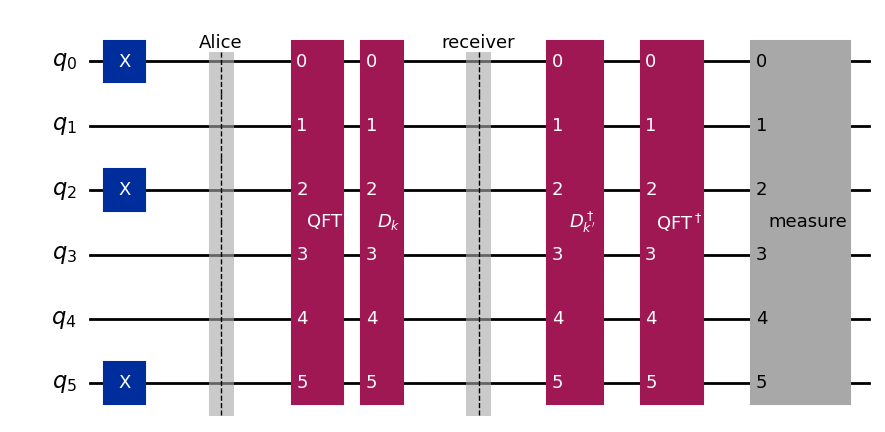

In [7]:
# Drawing only: labelled blocks instead of the 64-parameter DiagonalGate
def block(name, label):
    """Opaque block on all message qubits, used only for the drawing."""
    return Gate(name=name, num_qubits=N_QUBITS, params=[], label=label)

qc = prepare_message(N_QUBITS, M_EX)                 # X gates prepare |37> = |100101>
qc.barrier(label="Alice")
qc.append(block("qft_blk", "QFT"), range(N_QUBITS))
qc.append(block("dk_blk", "$D_k$"), range(N_QUBITS))
qc.barrier(label="receiver")
qc.append(block("dkp_blk", "$D_{k'}^\\dagger$"), range(N_QUBITS))
qc.append(block("iqft_blk", "QFT$^\\dagger$"), range(N_QUBITS))
qc.append(block("meas_blk", "measure"), range(N_QUBITS))   # simulated as exact probabilities

fig = qc.draw("mpl", fold=-1)
fig.savefig("fig_circuit.pdf", bbox_inches="tight")
fig

## 5. Simulate all message-key pairs

Strategy index $s$: $0..K-1$ = decode with key $s$, $K$ = no phase correction, $K+1$ = direct measurement.

`P[i, k, s, j]` = probability of outcome $j$ for message `messages[i]` locked with key $k$.
The message and key of every experiment are stored, so the correct answer is always known.

In [8]:
def run_experiment(n, K, seed=SEED, binary=False, n_messages=None, linear=False):
    d = 2**n
    theta = make_codebook(n, K, seed, binary, linear)
    if n_messages is None or n_messages >= d:
        messages = np.arange(d)                                    # all messages (n <= 6)
    else:                                                          # fixed random subset (larger n)
        messages = np.sort(np.random.default_rng(seed + 1).choice(d, n_messages, replace=False))

    locks = [lock_circuit(n, theta[k]) for k in range(K)]
    # decoders depend only on the key: compile them once into Operators
    unlocks = [Operator(unlock_circuit(n, theta[s])) for s in range(K)] + [Operator(unlock_circuit(n))]

    P = np.zeros((len(messages), K, K + 2, d))
    psi = np.zeros((len(messages), K, d), dtype=complex)
    for i, m in enumerate(messages):
        for k in range(K):
            sv = Statevector.from_instruction(prepare_message(n, m).compose(locks[k]))  # |psi_{m,k}>
            psi[i, k] = sv.data
            for s, U in enumerate(unlocks):
                P[i, k, s] = probs(sv.evolve(U))
            P[i, k, K + 1] = probs(sv)                              # direct measurement
    return {"n": n, "d": d, "K": K, "theta": theta, "messages": messages, "P": P, "psi": psi}

## 6. Metrics: recovery probability, entropy, Eve's information

In [9]:
def entropy_bits(p):
    p = np.asarray(p)
    p = p[p > 1e-12]
    return float(-np.sum(p * np.log2(p)))

def haar_entropy(d):
    """Average outcome entropy (bits) of a random pure state in dimension d: (H_d - 1)/ln 2."""
    return float(np.sum(1.0 / np.arange(2, d + 1)) / np.log(2))

def mutual_info(channel):
    """I(M;J) in bits for uniform messages; channel[i, j] = P(j | message i)."""
    return entropy_bits(channel.mean(axis=0)) - np.mean([entropy_bits(row) for row in channel])

def holevo_bits(psi):
    """Holevo quantity of Eve's ensemble rho_m = (1/K) sum_k |psi_mk><psi_mk| (uniform messages)."""
    rhos = [np.einsum("ka,kb->ab", p, p.conj()) / len(p) for p in psi]
    vn = lambda rho: entropy_bits(np.clip(np.linalg.eigvalsh(rho), 0, None))
    return vn(np.mean(rhos, axis=0)) - np.mean([vn(r) for r in rhos])

def summarize(res):
    P, msgs, K, d = res["P"], res["messages"], res["K"], res["d"]
    rec = np.array([P[i, :, :, m] for i, m in enumerate(msgs)])   # rec[i,k,s] = P(recover m)
    H = np.apply_along_axis(entropy_bits, -1, P)                  # H[i,k,s] = entropy of outcomes
    same = np.eye(K, dtype=bool)                                  # decoding key == true key
    eve = [mutual_info(P[:, :, s, :].mean(axis=1)) for s in range(K + 2)]   # Eve: k unknown
    return {
        "n": res["n"], "d": d, "K": K,
        "p_correct": rec[:, :, :K][:, same].mean(),
        "dev_correct": np.abs(1 - rec[:, :, :K][:, same]).max(),
        "H_correct": H[:, :, :K][:, same].mean(),
        "p_wrong": rec[:, :, :K][:, ~same].mean(),
        "p_wrong_pairs": rec[:, :, :K][:, ~same].mean(axis=0),
        "H_wrong": H[:, :, :K][:, ~same].mean(),
        "p_nocorr": rec[:, :, K].mean(), "H_nocorr": H[:, :, K].mean(),
        "p_direct": rec[:, :, K + 1].mean(), "H_direct": H[:, :, K + 1].mean(),
        "I_guess": max(eve[:K]), "I_nocorr": eve[K], "I_direct": eve[K + 1],
        "chi": holevo_bits(res["psi"]),
    }

def show(S):
    print(f"n={S['n']} d={S['d']} K={S['K']}  (1/d={1/S['d']:.4f}, random-state entropy={haar_entropy(S['d']):.2f} bits)")
    print(f"  correct key         P(m)={S['p_correct']:.4f}  H={S['H_correct']:.2f}  max|1-P|={S['dev_correct']:.1e}")
    print(f"  wrong key           P(m)={S['p_wrong']:.4f}  H={S['H_wrong']:.2f}")
    print(f"  no phase correction P(m)={S['p_nocorr']:.4f}  H={S['H_nocorr']:.2f}")
    print(f"  direct measurement  P(m)={S['p_direct']:.4f}  H={S['H_direct']:.2f}")
    print(f"  Eve: key guess I={S['I_guess']:.2f}, no correction I={S['I_nocorr']:.2f}, direct I={abs(S['I_direct']):.2f} bits")
    print(f"  Holevo chi={S['chi']:.2f} bits  (n - log2 K = {np.log2(S['d'] / S['K']):.2f})")

## 7. Main experiment: $n = 6$, $d = M = 64$, $K = 4$ (report Table I, Fig. 2)

In [10]:
t0 = time.perf_counter()
main = run_experiment(N_QUBITS, N_KEYS)
time_main = time.perf_counter() - t0
S = summarize(main)
show(S)
print(f"runtime of the main experiment: {time_main:.1f} s")

rec_pairs = np.array([main["P"][i, :, :N_KEYS, m] for i, m in enumerate(main["messages"])]).mean(axis=0)
print("\nP(recover m): rows = true key k, columns = decoding key k'")
print(np.round(rec_pairs, 4))

n=6 d=64 K=4  (1/d=0.0156, random-state entropy=5.40 bits)
  correct key         P(m)=1.0000  H=0.00  max|1-P|=2.4e-15
  wrong key           P(m)=0.0293  H=5.39
  no phase correction P(m)=0.0243  H=5.42
  direct measurement  P(m)=0.0156  H=6.00
  Eve: key guess I=1.02, no correction I=0.16, direct I=0.00 bits
  Holevo chi=4.06 bits  (n - log2 K = 4.00)
runtime of the main experiment: 6.2 s

P(recover m): rows = true key k, columns = decoding key k'
[[1.     0.028  0.0028 0.0292]
 [0.028  1.     0.0258 0.0371]
 [0.0028 0.0258 1.     0.0527]
 [0.0292 0.0371 0.0527 1.    ]]


In [11]:
# Check 1: every distribution depends only on j - m, i.e. P(.|m) = P(.|0) shifted by m
P = main["P"]
shift_dev = max(np.abs(P[m, k, s] - np.roll(P[0, k, s], m)).max()
                for m in main["messages"] for k in range(N_KEYS) for s in range(N_KEYS + 2))
print(f"max deviation from the shift structure: {shift_dev:.1e}")

# Check 2: analytic kernel, P(j | m=0) = |c(j)|^2 with c = FFT(leftover phases) / d
d = 2**N_QUBITS
x = np.arange(d)
F_dft = np.exp(2j * np.pi * np.outer(x, x) / d) / np.sqrt(d)   # |m> -> sum_x e^{2 pi i m x/d}|x>/sqrt(d)
print("QFTGate follows this convention:", np.allclose(Operator(QFTGate(N_QUBITS)).data, F_dft))
th = main["theta"]
kernel_dev = 0.0
for k in range(N_KEYS):
    for s in range(N_KEYS + 1):                                  # decoding keys 0..K-1 and "no key"
        leftover = th[k] - (th[s] if s < N_KEYS else 0.0)
        c = np.fft.fft(np.exp(1j * leftover)) / d
        kernel_dev = max(kernel_dev, np.abs(P[0, k, s] - np.abs(c) ** 2).max())
print(f"max deviation between circuit and the analytic kernel: {kernel_dev:.1e}")

max deviation from the shift structure: 1.5e-15
QFTGate follows this convention: True
max deviation between circuit and the analytic kernel: 2.0e-15


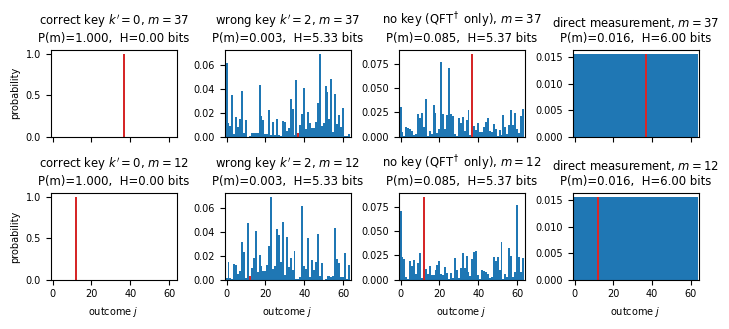

In [12]:
# Report Fig. 2: two selected messages (rows) and the four read-outs (columns)
d = 2**N_QUBITS
cols = [(K_EX, f"correct key $k'={K_EX}$"), (KP_EX, f"wrong key $k'={KP_EX}$"),
        (N_KEYS, "no key (QFT$^\\dagger$ only)"), (N_KEYS + 1, "direct measurement")]
with plt.rc_context({"font.size": 7}):
    fig, axes = plt.subplots(2, 4, figsize=(7.16, 3.3), sharex=True)
    for row, m in enumerate([M_EX, M_EX2]):
        for ax, (s, title) in zip(axes[row], cols):
            p = main["P"][m, K_EX, s]
            ax.bar(range(d), p, width=1.0, color=["tab:red" if j == m else "tab:blue" for j in range(d)])
            ax.set_title(f"{title}, $m={m}$\nP(m)={p[m]:.3f},  H={entropy_bits(p):.2f} bits")
            ax.set_xlim(-1, d)
        axes[row, 0].set_ylabel("probability")
    for ax in axes[1]:
        ax.set_xlabel("outcome $j$")
    fig.tight_layout()
    fig.savefig("fig_distributions.pdf", bbox_inches="tight")
    plt.show()

In [13]:
# Simpler variant: phases restricted to {0, pi}
main_bin = run_experiment(N_QUBITS, N_KEYS, binary=True)
S_bin = summarize(main_bin)
show(S_bin)

n=6 d=64 K=4  (1/d=0.0156, random-state entropy=5.40 bits)
  correct key         P(m)=1.0000  H=0.00  max|1-P|=8.9e-16
  wrong key           P(m)=0.0220  H=5.43
  no phase correction P(m)=0.0032  H=5.32
  direct measurement  P(m)=0.0156  H=6.00
  Eve: key guess I=0.98, no correction I=0.21, direct I=0.00 bits
  Holevo chi=4.05 bits  (n - log2 K = 4.00)


## 8. Classical comparison and codebook variation (report Sec. V, VII-A)

In [14]:
# Classical comparison: linear masks theta_x = 2 pi s_k x / d turn the circuit into a shift cipher
S_lin = summarize(run_experiment(N_QUBITS, N_KEYS, linear=True))
show(S_lin)   # expected: Eve's simple attacks already reach chi = n - log2 K = 4 bits -> nothing is locked

n=6 d=64 K=4  (1/d=0.0156, random-state entropy=5.40 bits)
  correct key         P(m)=1.0000  H=0.00  max|1-P|=3.1e-15
  wrong key           P(m)=0.0000  H=0.00
  no phase correction P(m)=0.0000  H=0.00
  direct measurement  P(m)=0.0156  H=6.00
  Eve: key guess I=4.00, no correction I=4.00, direct I=0.00 bits
  Holevo chi=4.00 bits  (n - log2 K = 4.00)


In [15]:
# Ten further codebooks (n = 6, K = 4, all messages): codebook-to-codebook variation
seed_runs = [summarize(run_experiment(N_QUBITS, N_KEYS, seed=s)) for s in SEEDS]

def mean_std(key, runs=seed_runs):
    v = np.array([r[key] for r in runs])
    return v.mean(), v.std(ddof=1)

for key in ["p_wrong", "H_wrong", "p_nocorr", "I_guess", "chi"]:
    mu, sd = mean_std(key)
    print(f"{key:9s}: {mu:.4f} +- {sd:.4f}")
print(f"expected spread of p_wrong for one codebook ~ 1/(d sqrt 6) = {1/(2**N_QUBITS*np.sqrt(6)):.4f}")

p_wrong  : 0.0198 +- 0.0057
H_wrong  : 5.3877 +- 0.0475
p_nocorr : 0.0167 +- 0.0092
I_guess  : 0.9813 +- 0.0472
chi      : 4.0426 +- 0.0126
expected spread of p_wrong for one codebook ~ 1/(d sqrt 6) = 0.0064


## 9. Circuit cost and different $n$ and $K$ (report Sec. IV-D, VI; Tables II-III)

In [16]:
# Circuit cost after transpilation to the basis {CX, Rz, sqrt(X), X}
BASIS = ["cx", "rz", "sx", "x"]

def circuit_cost(n, seed=SEED):
    theta_k = make_codebook(n, 1, seed)[0]
    qft = QuantumCircuit(n)
    qft.append(QFTGate(n), range(n))
    diag = QuantumCircuit(n)
    diag.append(DiagonalGate(list(np.exp(1j * theta_k))), range(n))
    tr = lambda qc: transpile(qc, basis_gates=BASIS, optimization_level=1)
    lock = tr(lock_circuit(n, theta_k))
    return {"cx_qft": tr(qft).count_ops().get("cx", 0),
            "cx_diag": tr(diag).count_ops().get("cx", 0),
            "cx_lock": lock.count_ops().get("cx", 0),
            "depth_lock": lock.depth()}

cost6 = circuit_cost(N_QUBITS)
print(cost6)

{'cx_qft': 39, 'cx_diag': 62, 'cx_lock': 101, 'depth_lock': 162}


In [17]:
def write_table(path, header, rows, colspec):
    with open(path, "w") as f:
        f.write(f"\\begin{{tabular}}{{{colspec}}}\n\\toprule\n{header} \\\\\n\\midrule\n")
        for row in rows:
            f.write(" & ".join(row) + " \\\\\n")
        f.write("\\bottomrule\n\\end{tabular}\n")

# Scan over n (K = 4). For n > 6: fixed random subset of 32 messages, all keys (exact by shift invariance).
scan_n = []
for n in [4, 5, 6, 7, 8]:
    n_msg = None if n <= 6 else 32
    t0 = time.perf_counter()
    r = summarize(run_experiment(n, N_KEYS, n_messages=n_msg))
    r["time"] = time.perf_counter() - t0
    if n == N_QUBITS:
        runs = seed_runs                                   # already computed above
    else:
        runs = [summarize(run_experiment(n, N_KEYS, seed=s, n_messages=n_msg)) for s in SEEDS]
    r["p_wrong_mean"], r["p_wrong_std"] = mean_std("p_wrong", runs)
    r["H_wrong_mean"], _ = mean_std("H_wrong", runs)
    r.update(circuit_cost(n))
    scan_n.append(r)
    print(f"n={n}: P_wrong={r['p_wrong_mean']:.4f}+-{r['p_wrong_std']:.4f} (1/d={2.0**-n:.4f})  "
          f"H_wrong={r['H_wrong_mean']:.2f} (random {haar_entropy(2**n):.2f})  "
          f"CX QFT={r['cx_qft']}  CX D_k={r['cx_diag']}  depth={r['depth_lock']}  time={r['time']:.1f}s")

write_table("table_n.tex",
            r"$n$ & $1/d$ & $P_{\rm wrong}$ & $H_{\rm wrong}$ & $H_{\rm rand}$ & CX (QFT) & CX ($D_k$) & depth & time [s]",
            [[str(r["n"]), f"{1/r['d']:.4f}", f"{r['p_wrong_mean']:.4f} $\\pm$ {r['p_wrong_std']:.4f}",
              f"{r['H_wrong_mean']:.2f}", f"{haar_entropy(r['d']):.2f}", str(r["cx_qft"]),
              str(r["cx_diag"]), str(r["depth_lock"]), f"{r['time']:.1f}"] for r in scan_n],
            "ccccccccc")

n=4: P_wrong=0.0633+-0.0216 (1/d=0.0625)  H_wrong=3.39 (random 3.43)  CX QFT=18  CX D_k=14  depth=54  time=0.4s
n=5: P_wrong=0.0287+-0.0126 (1/d=0.0312)  H_wrong=4.41 (random 4.41)  CX QFT=26  CX D_k=30  depth=92  time=1.4s
n=6: P_wrong=0.0198+-0.0057 (1/d=0.0156)  H_wrong=5.39 (random 5.40)  CX QFT=39  CX D_k=62  depth=162  time=6.1s
n=7: P_wrong=0.0095+-0.0034 (1/d=0.0078)  H_wrong=6.40 (random 6.40)  CX QFT=51  CX D_k=126  depth=296  time=7.7s
n=8: P_wrong=0.0039+-0.0014 (1/d=0.0039)  H_wrong=7.40 (random 7.39)  CX QFT=68  CX D_k=254  depth=558  time=16.3s


In [18]:
# Scan over K (n = 6, all messages)
scan_K = []
for Kx in [2, 4, 8, 16]:
    scan_K.append(summarize(run_experiment(N_QUBITS, Kx)))
    r = scan_K[-1]
    print(f"K={Kx:2d}: P_wrong={r['p_wrong']:.4f}  H_wrong={r['H_wrong']:.2f}  "
          f"I_guess={r['I_guess']:.2f}  chi={r['chi']:.2f}  (n-log2K={N_QUBITS - np.log2(Kx):.0f})")

write_table("table_K.tex",
            r"$K$ & bits & $P_{\rm wrong}$ & $H_{\rm wrong}$ & $I_{\rm guess}$ & $\chi$ & $n-\log_2K$",
            [[str(r["K"]), f"{np.log2(r['K']):.0f}", f"{r['p_wrong']:.4f}", f"{r['H_wrong']:.2f}",
              f"{r['I_guess']:.2f}", f"{r['chi']:.2f}", f"{N_QUBITS - np.log2(r['K']):.0f}"] for r in scan_K],
            "ccccccc")

K= 2: P_wrong=0.0280  H_wrong=5.31  I_guess=2.44  chi=5.02  (n-log2K=5)
K= 4: P_wrong=0.0293  H_wrong=5.39  I_guess=1.02  chi=4.06  (n-log2K=4)
K= 8: P_wrong=0.0222  H_wrong=5.40  I_guess=0.41  chi=3.11  (n-log2K=3)
K=16: P_wrong=0.0198  H_wrong=5.41  I_guess=0.16  chi=2.22  (n-log2K=2)


## 10. Export numbers for the report

In [19]:
def sci(x):
    mant, exp = f"{max(float(x), 1e-17):.1e}".split("e")
    return f"${mant}\\times 10^{{{int(exp)}}}$"

ps_mu, ps_sd = mean_std("p_wrong")
hs_mu, hs_sd = mean_std("H_wrong")
ig_mu, ig_sd = mean_std("I_guess")

macros = {
    # main experiment (n = 6, K = 4, seed 2026)
    "PCorrect": f"{S['p_correct']:.4f}", "HCorrect": f"{S['H_correct']:.2f}",
    "CorrectDev": sci(S["dev_correct"]),
    "PWrong": f"{S['p_wrong']:.4f}", "HWrong": f"{S['H_wrong']:.2f}",
    "PWrongMin": f"{S['p_wrong_pairs'].min():.4f}", "PWrongMax": f"{S['p_wrong_pairs'].max():.4f}",
    "PNoCorr": f"{S['p_nocorr']:.4f}", "HNoCorr": f"{S['H_nocorr']:.2f}",
    "PDirect": f"{S['p_direct']:.4f}", "HDirect": f"{S['H_direct']:.2f}",
    "HHaar": f"{haar_entropy(S['d']):.2f}",
    "IGuess": f"{S['I_guess']:.2f}", "INoCorr": f"{S['I_nocorr']:.2f}",
    "IDirect": f"{abs(S['I_direct']):.2f}", "Holevo": f"{S['chi']:.2f}",
    "PWrongBin": f"{S_bin['p_wrong']:.4f}", "HWrongBin": f"{S_bin['H_wrong']:.2f}",
    # checks
    "ShiftDev": sci(shift_dev), "KernelDev": sci(kernel_dev),
    "CorrectDevAll": sci(max(r["dev_correct"] for r in scan_n)),
    # one-qubit worked example
    "WEDelta": f"{Delta:.2f}", "WEPcirc": f"{P_circ:.4f}", "WEPformula": f"{P_formula:.4f}",
    # computational resources
    "CXQFT": str(cost6["cx_qft"]), "CXDiag": str(cost6["cx_diag"]),
    "DepthLock": str(cost6["depth_lock"]), "TimeMain": f"{time_main:.1f}",
    # ten further codebooks
    "PWrongSeeds": f"{ps_mu:.4f}", "PWrongSeedsStd": f"{ps_sd:.4f}",
    "HWrongSeeds": f"{hs_mu:.2f}", "HWrongSeedsStd": f"{hs_sd:.2f}",
    "IGuessSeeds": f"{ig_mu:.2f}", "IGuessSeedsStd": f"{ig_sd:.2f}",
    # classical shift cipher (linear masks)
    "IGuessLin": f"{S_lin['I_guess']:.2f}", "INoCorrLin": f"{S_lin['I_nocorr']:.2f}",
    "HolevoLin": f"{S_lin['chi']:.2f}",
}
with open("results.tex", "w") as f:
    for name, value in macros.items():
        f.write(f"\\newcommand{{\\{name}}}{{{value}}}\n")
print(open("results.tex").read())

\newcommand{\PCorrect}{1.0000}
\newcommand{\HCorrect}{0.00}
\newcommand{\CorrectDev}{$2.4\times 10^{-15}$}
\newcommand{\PWrong}{0.0293}
\newcommand{\HWrong}{5.39}
\newcommand{\PWrongMin}{0.0028}
\newcommand{\PWrongMax}{0.0527}
\newcommand{\PNoCorr}{0.0243}
\newcommand{\HNoCorr}{5.42}
\newcommand{\PDirect}{0.0156}
\newcommand{\HDirect}{6.00}
\newcommand{\HHaar}{5.40}
\newcommand{\IGuess}{1.02}
\newcommand{\INoCorr}{0.16}
\newcommand{\IDirect}{0.00}
\newcommand{\Holevo}{4.06}
\newcommand{\PWrongBin}{0.0220}
\newcommand{\HWrongBin}{5.43}
\newcommand{\ShiftDev}{$1.5\times 10^{-15}$}
\newcommand{\KernelDev}{$2.0\times 10^{-15}$}
\newcommand{\CorrectDevAll}{$2.4\times 10^{-15}$}
\newcommand{\WEDelta}{0.16}
\newcommand{\WEPcirc}{0.9937}
\newcommand{\WEPformula}{0.9937}
\newcommand{\CXQFT}{39}
\newcommand{\CXDiag}{62}
\newcommand{\DepthLock}{162}
\newcommand{\TimeMain}{6.2}
\newcommand{\PWrongSeeds}{0.0198}
\newcommand{\PWrongSeedsStd}{0.0057}
\newcommand{\HWrongSeeds}{5.39}
\newcommand{\HWron

In [20]:
# Bundle every file used by the report (upload these next to the .tex in Overleaf)
OUTPUT_FILES = ["results.tex", "table_n.tex", "table_K.tex", "fig_circuit.pdf", "fig_distributions.pdf"]
with zipfile.ZipFile("report_files.zip", "w") as z:
    for f in OUTPUT_FILES:
        z.write(f)
print("written:", OUTPUT_FILES, "-> report_files.zip")

try:                                   # Google Colab: download the zip directly
    from google.colab import files
    files.download("report_files.zip")
except ImportError:
    pass

written: ['results.tex', 'table_n.tex', 'table_K.tex', 'fig_circuit.pdf', 'fig_distributions.pdf'] -> report_files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>